---
title: "The 20 Million Votes: When a Projection Poses as a Count"
subtitle: "DS 2023 | Communicating with Data"
---


![U.S. House Midterm Votes, the original chart](https://virginia.box.com/shared/static/5q20mntzmrq5fonblvzojjfphnyqy26l.png)

**U.S. HOUSE MIDTERM VOTES** [Source](https://x.com/Sandra_G_Loftis/status/2119773643219575033?a=7X6PcMQ4rJppWfRS_g4&s=20).

Take a look the graph above.

It was posted on X on November 9, 2026, with the comment "Nothing remotely resembling reality here."

What does it make you believe happened in 2026?

## Overview

Days after the **2026 midterms**, charts like this one spread on social media.

They compare House votes by party in recent midterms.

They use a **grouped bar chart** showing votes ($y$) grouped by party ($x$) over years ($z$).

The message is in the last group: _Republicans held steady while Democrats gained about 20 million votes – apparently out of nowhere_.


```{note}
Several versions circulated with slightly different numbers.

One, posted on November 5 and reshared by the President, projected 70.4 million Democrat votes and 55.6 million Republican votes.

The version above shows 72 million and 54 million.
```

## Critical reproduction

In this notebook, we explore this claim through the method of **critique by reconstruction**, a form of what digital humanists call **critical making**.

```{note} Definition

**Critique by Reconstruction** is the practice of evaluating a quantitative claim or data visualization by rebuilding it from its primary source data. 

Rather than judging a graphic at face value, you trace the pipeline of construction from raw numbers to rendered geometry, write code from scratch to reproduce the visual, and build alternative encodings to test whether the original design clarifies or distorts the underlying evidence.

In this way, the original claims associated with the visualization can be tested, errors or inconsistencies in the pipeline can be discovered, an alternate ways of visualizing the data may be proposed.
```

To evaluate the chart, we'll rebuild it from its own numbers.

Along the way, we may catch errors or confirm the validity of the chart.

We will not, howver, be able to assess the **explanation** that the votes came from "nowhere."

Our guides are Cairo's *How Charts Lie* (charts that lie by displaying dubious data and by being poorly designed) and Tufte's **lie factor**.

```{note} Source

The data come from the **University of Florida Election Lab** estimate of 2026 ballots cast and the unofficial 2026 House count. See:

- [_Popular Vote Analytics_, November 12, 2026](https://popularvoteanalytics.org/).
- [_Political.org_, "2022 vs. 2026 Midterm Turnout by Party: What the Official Numbers Show So Far"](https://political.org/2026/11/08/2022-vs-2026-midterm-turnout-by-party-what-the-official-numbers-show-so-far/).

```

## Set Up

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='white')
PARTY_COLORS = ['tab:red', 'tab:blue']

Here are the chart's numbers, exactly as printed, in millions of votes.

You can check the earlier years against the House Clerk's *Statistics of the Congressional Election*.

In [66]:
chart = pd.DataFrame({
    'year':  [2010, 2014, 2018, 2022, 2026],
    'Republican': [45, 40, 51, 54, 54],
    'Democrat': [39, 35, 60, 51, 72],
}).set_index('year').astype(float)

chart

,Republican,Democrat
year,,
2010,45.0,39.0
2014,40.0,35.0
2018,51.0,60.0
2022,54.0,51.0
2026,54.0,72.0


## Rebuilding the chart

Let's draw the chart's own numbers as plain bars: zero baseline, no glow, no 3D.

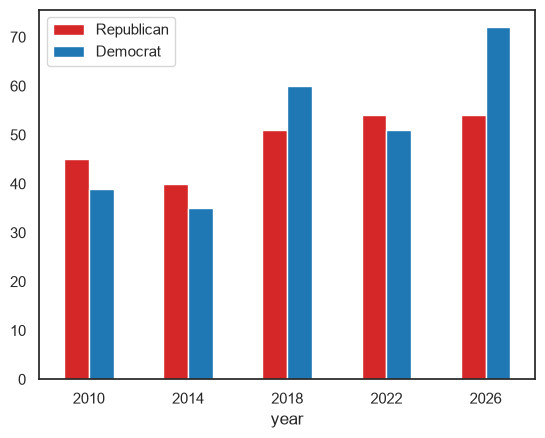

In [67]:
chart.plot.bar(rot=0, color=PARTY_COLORS)
plt.show()

Or, to add labels and other tweaks, we can do this.

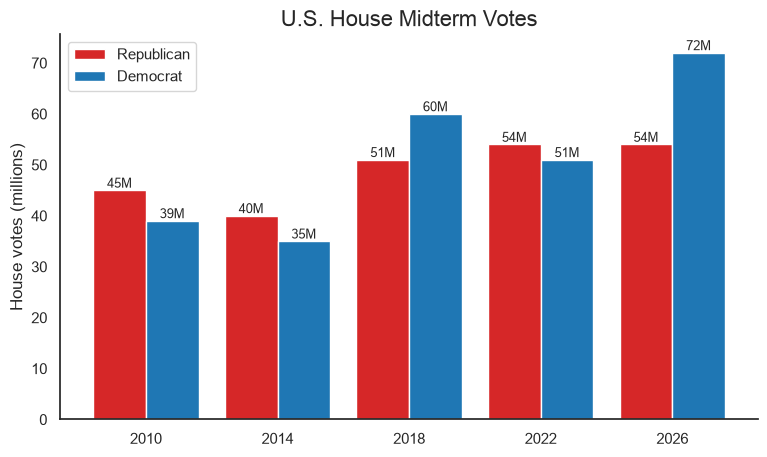

In [68]:
ax = chart.plot.bar(color=PARTY_COLORS, figsize=(9, 5), rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0fM', fontsize=9)
ax.set_xlabel('') # Year is unnecessary
ax.set_ylabel('House votes (millions)')
ax.set_title('U.S. House Midterm Votes', fontsize=16)
sns.despine()
plt.show()

Now: Compare this with the original.

Does the last blue bar look as dramatic here?

## Criticisms

### Critique 1: The chart mixes projections and counts

Look at the small print under the original. It says:

> *Preliminary / Projected*.

This means that every bar is a final count except the last pair, which is a forecast made while votes were still being counted.

The best-known version was made with about 85% of the vote counted.

Even though the last group is a projection, the claim "Republicans held steady" reads as if the data are final.

Let's fix this by putting the projection beside the count.

First, we find the actual count data.

In [69]:
# Unofficial House count, November 12, 2026 (Popular Vote Analytics)
counted_2026 = pd.Series({'Republican': 49.78, 'Democrat': 65.91})

Then let's combine the data.

In [70]:
compare = chart.copy().reset_index()
compare['status'] = np.where(compare['year'] == 2026, 'projected', 'counted')
compare = compare.set_index(['year','status'])
compare.loc[(2026, 'counted'), :] = counted_2026
compare

Republican  Democrat
year status                         
2010 counted         45.00     39.00
2014 counted         40.00     35.00
2018 counted         51.00     60.00
2022 counted         54.00     51.00
2026 projected       54.00     72.00
     counted         49.78     65.91

Now let's plot it.

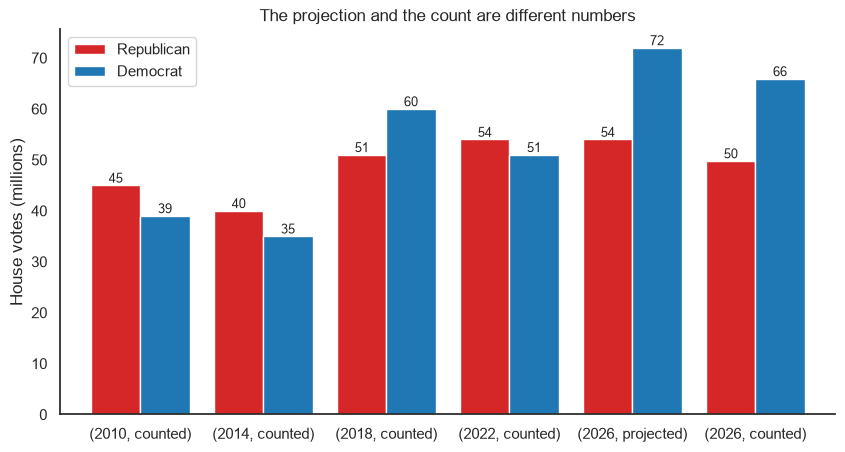

Republican  Democrat
year status                         
2026 projected         0.0      21.0
     counted          -4.2      14.9

In [71]:
ax = compare.plot.bar(color=PARTY_COLORS, figsize=(10, 5), rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9)
ax.set_xlabel('')
ax.set_ylabel('House votes (millions)')
ax.set_title('The projection and the count are different numbers')
sns.despine()
plt.show()

(compare.loc[[(2026, 'projected'), (2026, 'counted')]] - compare.loc[(2022, 'counted')]).round(1)

The projection has Republicans flat and Democrats up 21 million.

The count has Republicans down about 4 million and Democrats up about 15 million.

"Republicans held steady" came from the projection's assumptions, not from votes.

```{note}
Cairo would call this **dubious data**: the chart presents a forecast as if it were the same kind of number as the bars beside it.
```

What should a chart do to show that one bar is a forecast?

### Critique 2: A total larger than the turnout

We know that a House vote is always smaller ballots cast.

This is because some voters skip the House race, and some races have only one candidate.

Let's compare the projected vote count to the number of ballots.

We get the total ballot value from the University of Florida's Election Lab.

Note that 2026 is a preliminary estimate

In [72]:
ballots = pd.DataFrame([112.03, 123.17], columns=['Ballots'], index=[2022,2026])
ballots.index.name = 'year'
ballots

,Ballots
year,
2022,112.03
2026,123.17


In [73]:
totals = compare.join(ballots).dropna()
totals

Republican  Democrat  Ballots
year status                                  
2022 counted         54.00     51.00   112.03
2026 projected       54.00     72.00   123.17
     counted         49.78     65.91   123.17

In [74]:
totals['Both'] = totals.Republican + totals.Democrat
totals['Excess'] = totals.Ballots - totals.Both
totals['Percent'] = (totals.Both / totals.Ballots * 100).round(2)
totals[['Ballots','Both','Excess','Percent']]

Ballots    Both  Excess  Percent
year status                                     
2022 counted     112.03  105.00    7.03    93.72
2026 projected   123.17  126.00   -2.83   102.30
     counted     123.17  115.69    7.48    93.93

The projection needs 126 million House votes from about 123 million ballots.

That's more than 100% of everyone who voted, before allowing for anyone who skipped the race.

The other counts, about 94% of ballots, are in the normal range.

### Critique 3: The bar that grew too fast

Tufte defines the **lie factor** of a graphic as

$$\text{lie factor} = \frac{\text{size of the effect shown in the graphic}}{\text{size of the effect in the data}}$$

where an effect is a relative change, such as (new − old) / old.

An honest graphic has a lie factor of 1.

Tufte suggested that anything outside about 0.95 to 1.05 is a substantial distortion.

To measure the effect shown in the graphic, we need each bar's drawn height.

These heights were measured from the screenshot, in pixels, by following each blue bar's column from the baseline up to its top.

The optional cell after this one shows how.

In [75]:
drawn = pd.DataFrame({
    'votes':  chart['Democrat'],
    'pixels': [116, 104, 194, 158, 356],
})
drawn['pixels per million'] = (drawn.pixels / drawn.votes).round(2)
drawn

,votes,pixels,pixels per million
year,,,
2010,39.0,116,2.97
2014,35.0,104,2.97
2018,60.0,194,3.23
2022,51.0,158,3.10
2026,72.0,356,4.94


```{tip}
**Optional: measure the bars yourself.** Save the cropped chart as `house-midterm-votes.png` next to this notebook and run the next cell.
It finds each blue bar along the bottom of the chart and climbs its column until the color stops.
Glow effects make the edges fuzzy, so expect a few pixels of difference.
```

In [76]:
from pathlib import Path

if Path('./midterm-votes.png').exists():

    from PIL import Image
    img = np.asarray(Image.open('midterm-votes.png').convert('RGB')).astype(int)
    blue = (img[..., 2] > 140) & (img[..., 2] - img[..., 0] > 50)

    baseline = 392                                    # a row just above the bars' bottom edge
    columns = np.flatnonzero(blue[baseline])
    breaks = np.flatnonzero(np.diff(columns) > 2)
    starts = np.r_[columns[0], columns[breaks + 1]]
    ends = np.r_[columns[breaks], columns[-1]]

    heights = []
    for i, start in enumerate(starts):
        if ends[i] - start < 10:
            continue
        x = (start + ends[i]) // 2
        y, gap, top = baseline, 0, baseline
        while y > 0 and gap <= 22:                    # tolerate gaps where the labels sit
            if blue[y, x]:
                top, gap = y, 0
            else:
                gap += 1
            y -= 1
        heights.append(baseline - top)
    print('Measured heights (pixels):', heights)
else:
    print('Image not found: using the heights in the table above.')

Measured heights (pixels): [112, 100, 190, 154, 352]


In 2010 through 2022 the bars use a steady scale.

Let's fit that scale with a straight line, then ask how tall a 72-million bar should be.

In [77]:
honest = drawn.loc[[2010, 2014, 2018, 2022]]
slope, intercept = np.polyfit(honest.votes, honest.pixels, 1)

expected = intercept + slope * 72
implied_votes = (drawn.loc[2026, 'pixels'] - intercept) / slope

data_effect = (72 - 51) / 51
graphic_effect = (drawn.loc[2026, 'pixels'] - drawn.loc[2022, 'pixels']) / drawn.loc[2022, 'pixels']

print(f'Scale from 2010-2022: {slope:.2f} pixels per million votes')
print(f'A 72-million bar should be about {expected:.0f} pixels; it is {drawn.loc[2026, "pixels"]}.')
print(f'Its height corresponds to about {implied_votes:.0f} million votes.')
print(f'Change 2022 to 2026: {data_effect:.0%} in the data, {graphic_effect:.0%} in the graphic.')
print(f'Lie factor: {graphic_effect / data_effect:.1f}')

Scale from 2010-2022: 3.60 pixels per million votes
A 72-million bar should be about 236 pixels; it is 356.
Its height corresponds to about 105 million votes.
Change 2022 to 2026: 41% in the data, 125% in the graphic.
Lie factor: 3.0


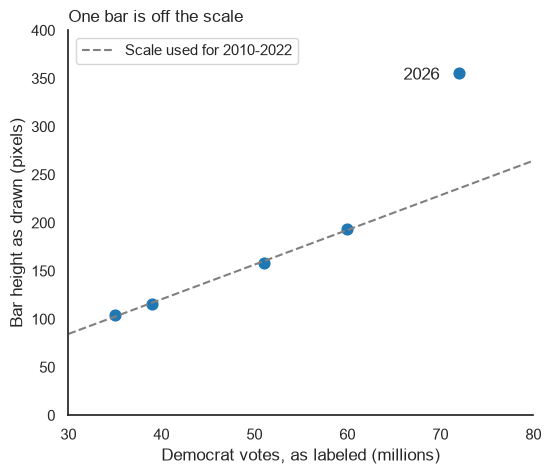

In [78]:
ax = drawn.plot.scatter(x='votes', y='pixels', s=60, color='tab:blue', figsize=(6, 5))
ax.axline((0, intercept), slope=slope, color='gray', ls='--', label='Scale used for 2010-2022')
ax.annotate('2026', (72, drawn.loc[2026, 'pixels']), xytext=(-40, -5), textcoords='offset points')
ax.set_xlim(30, 80)
ax.set_ylim(0, 400)
ax.set_xlabel('Democrat votes, as labeled (millions)')
ax.set_ylabel('Bar height as drawn (pixels)')
ax.set_title('One bar is off the scale', loc='left')
ax.legend(loc='upper left')
sns.despine()
plt.show()

The 2010-2022 bars fall on one line.

The 2026 bar sits far above it, drawn as tall as a bar for about 105 million votes would be.

A 41% increase is shown as a 125% increase, a lie factor of about 3.

The glow and 3D rendering add to it: the least certain number in the chart is also the brightest.

Why might a chart maker hand-draw bars instead of plotting them from data?

In [16]:
cartoon = pd.DataFrame({
    'party':  ['Republican'] * 5 + ['Democrat'] * 5,
    'year':   [2010, 2014, 2018, 2022, 2026] * 2,
    'votes':  [45, 40, 51, 54, 54, 39, 35, 60, 51, 72],
    'pixels': [217, 187, 241, 266, 252, 180, 152, 330, 239, 600],
})

others = cartoon[~((cartoon.party == 'Democrat') & (cartoon.year == 2026))]
slope2, intercept2 = np.polyfit(others.votes, others.pixels, 1)
others_resid = others.pixels - (intercept2 + slope2 * others.votes)

print(f'The other nine bars fit one scale to within {others_resid.abs().max():.0f} pixels.')
print(f'A 72-million bar should be about {intercept2 + slope2 * 72:.0f} pixels; it is 600.')
print(f'Its height corresponds to about {(600 - intercept2) / slope2:.0f} million votes.')

The other nine bars fit one scale to within 24 pixels.
A 72-million bar should be about 380 pixels; it is 600.
Its height corresponds to about 107 million votes.


Nine bars on one scale, and the same one bar drawn as if it were over 100 million.

Two different artists, or two runs of an image generator, made the same exaggeration.

That suggests the second chart was copied from the first, distortion and all.

When a chart is redrawn from another chart instead of from data, its errors travel with it.

### Critique 4: The chart's own history

The chart invites us to look at one change, 2022 to 2026.

But it shows four changes.

Let's compute them all.

```{tip}

We do this with `df.diff()`. 

This calculates the difference of a DataFrame element compared with another
element in the DataFrame, where the default is element in previous row.
```

In [79]:
changes = chart.diff().dropna()
changes.index = ['2010 to 2014', '2014 to 2018', '2018 to 2022', '2022 to 2026 (projected)']
changes

,Republican,Democrat
2010 to 2014,-5.0,-4.0
2014 to 2018,11.0,25.0
2018 to 2022,3.0,-9.0
2022 to 2026 (projected),0.0,21.0


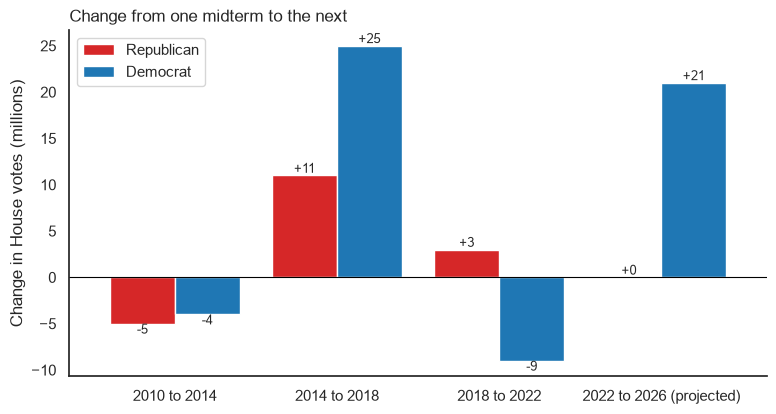

In [80]:
ax = changes.plot.bar(color=PARTY_COLORS, figsize=(9, 4.5), rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%+.0f', fontsize=9)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('')
ax.set_ylabel('Change in House votes (millions)')
ax.set_title('Change from one midterm to the next', loc='left')
sns.despine()
plt.show()

From 2014 to 2018, Democrat House votes rose by 25 million.

That was also a midterm with Donald Trump in the White House, and it's a bigger jump than the 21 million the chart projects for 2026.

The chart contains its own counterexample.

Midterm turnout also swings with the national mood: 2014 was a low-turnout year, and 2018 the highest-turnout midterm in a century.

What would you need to know before calling a jump between two midterms "impossible"?

### Critique 5: Who keeps their voters

In every midterm, the party out of the White House tends to turn out its voters better than the president's party does.

Let's look at each midterm's two-party share for the party that did **not** hold the presidency.

In [81]:
keeps = pd.DataFrame(
    [(2010, 'Democrat', 'Republican'), 
    (2014, 'Democrat', 'Republican'), 
    (2018, 'Republican', 'Democrat'),
    (2022, 'Democrat', 'Republican'), 
    (2026, 'Republican', 'Democrat')],
    columns=['year','President','Out Party']
).set_index('year').join(compare)
keeps['Put Party Share %'] = (
    keeps[['Republican', 'Democrat']].max(axis=1) / 
    keeps[['Republican', 'Democrat']].sum(axis=1) * 100
).round(1)

In [82]:
keeps

President   Out Party  Republican  Democrat  \
year status                                                    
2010 counted      Democrat  Republican       45.00     39.00   
2014 counted      Democrat  Republican       40.00     35.00   
2018 counted    Republican    Democrat       51.00     60.00   
2022 counted      Democrat  Republican       54.00     51.00   
2026 projected  Republican    Democrat       54.00     72.00   
     counted    Republican    Democrat       49.78     65.91   

                Put Party Share %  
year status                        
2010 counted                 53.6  
2014 counted                 53.3  
2018 counted                 54.1  
2022 counted                 51.4  
2026 projected               57.1  
     counted                 57.0

The out-party won the House vote in all five midterms.

2026 is the largest out-party share of the five, about 57%, but 2018 and 2010 were not far behind.

A large swing against the president's party is the normal shape of a midterm, not a sign of votes appearing from nowhere.

Remember, though, that the 2026 count is still unofficial.

## A better chart

Here is the same history with one encoding for every year, counted numbers only, and the date of the count stated.

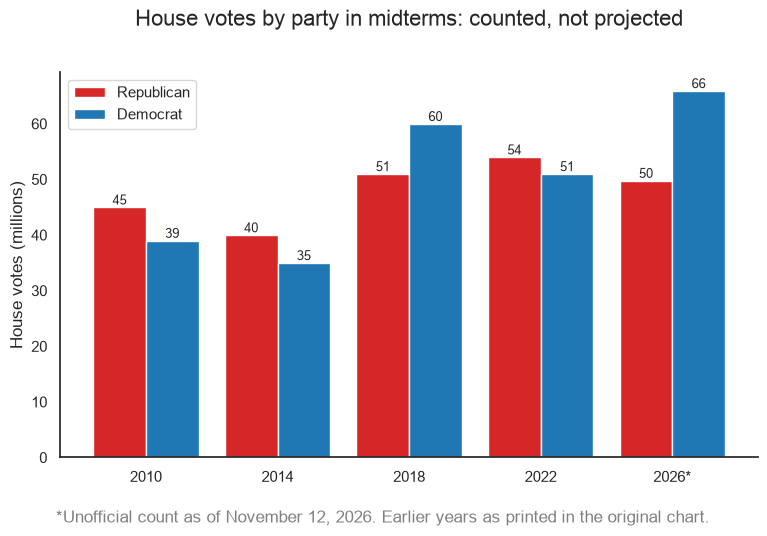

In [83]:
ax = counts.plot.bar(color=PARTY_COLORS, figsize=(9, 5), rot=0, width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=9)
ax.set_xticks(range(5), ['2010', '2014', '2018', '2022', '2026*'])
ax.set_xlabel('')
ax.set_ylabel('House votes (millions)')
ax.set_title('House votes by party in midterms: counted, not projected', fontsize=16, y=1.1)
plt.figtext(0.12, -0.02, '*Unofficial count as of November 12, 2026. Earlier years as printed in the original chart.',
            fontsize=12, color='gray')
sns.despine()
plt.show()

## Discussion

1. **Cairo, dubious data:** The original marks its projection with a small asterisk. Is that enough? What design choices would make a forecast unmistakable?
2. **Tufte, lie factor:** We measured a lie factor of about 3. Which design elements (glow, 3D, color, height) did the most to exaggerate the last bar?
3. **Plausibility:** Critique 2 needed only addition. List two other quick checks you could run on any vote-count chart.
4. **Selection:** The chart starts in 2010. How would it look if it started in 2014? In 2018? Why might a chart maker choose a starting year?
5. **Your turn:** Find another viral chart about the 2026 election. Run it through the four tests in this notebook. Which test catches the most?